# LightGBM idiomático — categóricas nativas, Optuna y SHAP
### Tesis de Maestría · Modelo de Valuación Automática (AVM) · Distrito Centro (Rosario)

## Motivación

El notebook 04 evaluó LightGBM con **one-hot** e hiperparámetros por **búsqueda aleatoria**, para
compararlo en **igualdad de condiciones** contra el Random Forest. Aquí exploramos LightGBM en su **forma
idiomática**, incorporando tres prácticas del modelo que no usa el baseline, y cerramos comparando ambas
versiones. La pregunta es si estas prácticas **aportan** desempeño o interpretabilidad frente al baseline.

- **Categóricas nativas.** LightGBM parte las variables categóricas de forma óptima (particiona el conjunto
  de niveles buscando el mejor corte, en lugar de expandir en columnas 0/1), lo que suele manejar mejor la
  **alta cardinalidad** —como `barrio`— y reduce la dimensión del problema (Ke et al., 2017; van Wyk, 2023).
  También aprovechamos que LightGBM maneja **valores faltantes de forma nativa**, por lo que no requiere
  imputación.
- **Optuna (búsqueda bayesiana) + early stopping.** En lugar de muestrear al azar, Optuna usa un muestreador
  **TPE** que concentra la búsqueda en las regiones prometedoras del espacio de hiperparámetros (Akiba et
  al., 2019). El **early stopping** elige el número de árboles automáticamente, deteniendo el *boosting*
  cuando el error de validación deja de mejorar.
- **SHAP.** Valores de Shapley para **interpretabilidad** (Lundberg & Lee, 2017): explican el aporte de cada
  variable a cada predicción y permiten leer, a nivel local y global, cómo el modelo arma la tasación (RQ5).

Mantenemos el **protocolo riguroso** de los otros notebooks: mismas particiones **group-aware**, **CV
anidada** (Optuna dentro del train de cada fold externo), reporte de **train y test** y análisis
**incremental S1→S4**.

## Metodología

- **Representación de datos:** categóricas como tipo `category` (splits nativos); numéricas sin escalar y
  **sin imputar** (LightGBM maneja faltantes). No hay one-hot.
- **Particionado:** `GroupKFold` (5 folds, grupo = `building_cluster_id`), las mismas que el resto.
- **Tuneo sin fuga:** para cada fold externo, un estudio de **Optuna** optimiza los hiperparámetros con CV
  **interna** group-aware; cada ajuste usa **early stopping** sobre su fold de validación. El fold de test
  externo no participa en la selección (ESL §7.10.2).
- **Reporte de train y test** por escenario (sesgo–varianza) e **incremental S1→S4**.
- **Interpretabilidad:** SHAP sobre el modelo final (S4).

> **Nota de ejecución.** El tuneo bayesiano anidado entrena muchos modelos; con *early stopping* cada
> ajuste es rápido, pero la corrida completa lleva varios minutos.

In [1]:
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import optuna
from optuna.samplers import TPESampler
import lightgbm as lgb
from lightgbm import LGBMRegressor, early_stopping, log_evaluation
import shap
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
optuna.logging.set_verbosity(optuna.logging.WARNING)

ROOT = Path.cwd()
while not (ROOT / "data" / "processed").exists() and ROOT != ROOT.parent: ROOT = ROOT.parent
sns.set_theme(style="whitegrid", context="notebook")
PAL, PAL2, ACCENT, MOR = "#2c6e91", "#c0562b", "#3a8f5e", "#7b5ea7"
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 130, "savefig.bbox": "tight",
                     "font.size": 11, "axes.titleweight": "bold", "axes.titlesize": 12.5, "figure.autolayout": True})

df = pd.read_csv(ROOT / "data" / "processed" / "zonaprop_v2_matriz_modelado_centro.csv.gz")
y = np.log1p(pd.to_numeric(df["eda_precio_usd"], errors="coerce").values)
groups = df["building_cluster_id"].values
feat_cols = [c for c in df.columns if c.startswith("feat_")]

S1 = ["eda_superficie_total_m2","eda_superficie_cubierta_m2","eda_ambientes","eda_dormitorios",
      "eda_banos","eda_cocheras","eda_toilette","eda_antiguedad_anos","eda_antiguedad_estado",
      "eda_disposicion","eda_orientacion","eda_tipo_operacion","eda_expensas",
      "fe_ratio_cubierta_total","fe_sup_por_ambiente","fe_banos_por_ambiente",
      "fe_dormitorios_por_ambiente","fe_tiene_cochera","fe_expensas_informadas"]
S2 = ["barrio_oficial_geo","eda_latitud","eda_longitud"]
S3 = [c for c in ["fe_dist_centro_km","fe_dist_rio_km","fe_dist_espacio_verde_km","fe_dens_comercios_300m"] if c in df.columns]
escen = {"S1":[c for c in S1 if c in df.columns],
         "S2":[c for c in S1+S2 if c in df.columns],
         "S3":[c for c in S1+S2+S3 if c in df.columns],
         "S4":[c for c in S1+S2+S3 if c in df.columns]+feat_cols}
CAT = {"eda_antiguedad_estado","eda_disposicion","eda_orientacion","eda_tipo_operacion","barrio_oficial_geo"}
SEED, N_IN, N_TRIALS = 42, 3, 40

def diseno(cols):
    "DataFrame tipado: categóricas como 'category', numéricas como float (NaN permitido)."
    X = pd.DataFrame(index=df.index)
    for c in cols:
        X[c] = df[c].astype("category") if c in CAT else pd.to_numeric(df[c], errors="coerce")
    return X
print(f"Matriz: {len(df):,} avisos · {df['building_cluster_id'].nunique():,} grupos · LightGBM idiomático · Optuna n_trials={N_TRIALS}")

Matriz: 4,765 avisos · 1,377 grupos · LightGBM idiomático · Optuna n_trials=40


## Búsqueda con Optuna y evaluación anidada

`nested` recorre los folds externos; en cada uno, Optuna busca hiperparámetros optimizando el RMSE de una
CV interna group-aware con early stopping, y luego se reajusta el mejor modelo (también con early stopping)
para predecir el fold de test. Devuelve métricas de **train** y **test** y las predicciones OOF.

In [2]:
FIJOS = dict(objective="regression", n_estimators=3000, random_state=SEED, n_jobs=-1,
             subsample_freq=1, verbose=-1)
CB = [early_stopping(50, verbose=False), log_evaluation(0)]

def espacio(trial):
    return dict(learning_rate=trial.suggest_float("learning_rate", 0.005, 0.2, log=True),
                num_leaves=trial.suggest_int("num_leaves", 15, 128),
                max_depth=trial.suggest_int("max_depth", 3, 14),
                min_child_samples=trial.suggest_int("min_child_samples", 5, 80),
                subsample=trial.suggest_float("subsample", 0.6, 1.0),
                colsample_bytree=trial.suggest_float("colsample_bytree", 0.6, 1.0),
                reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 20, log=True),
                reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 20, log=True))

def _rmse_log(yv, pv): return np.sqrt(mean_squared_error(yv, pv))

def tunear(X, yv, g, n_trials=N_TRIALS):
    def obj(trial):
        p = {**FIJOS, **espacio(trial)}; sc = []
        for itr, iva in GroupKFold(N_IN).split(X, yv, g):
            m = LGBMRegressor(**p).fit(X.iloc[itr], yv[itr], eval_set=[(X.iloc[iva], yv[iva])], callbacks=CB)
            sc.append(mean_squared_error(yv[iva], m.predict(X.iloc[iva])))
        return float(np.mean(sc))
    st = optuna.create_study(direction="minimize", sampler=TPESampler(seed=SEED))
    st.optimize(obj, n_trials=n_trials, show_progress_bar=False)
    return st.best_params

def ajustar(X, yv, g, params):
    "Reajusta con early stopping usando un fold group-aware como validación; devuelve modelo y el train usado."
    itr, iva = next(iter(GroupKFold(5).split(X, yv, g)))
    m = LGBMRegressor(**FIJOS, **params).fit(X.iloc[itr], yv[itr], eval_set=[(X.iloc[iva], yv[iva])], callbacks=CB)
    return m, itr

def nested(cols):
    X = diseno(cols); gkf = GroupKFold(5)
    tr_r2=[];te_r2=[];tr_rm=[];te_rm=[];te_mape=[]; oof=np.full(len(y),np.nan)
    for tr, te in gkf.split(X, y, groups):
        best = tunear(X.iloc[tr], y[tr], groups[tr])
        m, itr = ajustar(X.iloc[tr], y[tr], groups[tr], best)
        ptr = m.predict(X.iloc[tr].iloc[itr]); pte = m.predict(X.iloc[te]); oof[te]=pte
        tr_r2.append(r2_score(y[tr][itr], ptr)); te_r2.append(r2_score(y[te], pte))
        tr_rm.append(np.sqrt(mean_squared_error(np.expm1(y[tr][itr]), np.expm1(ptr))))
        te_rm.append(np.sqrt(mean_squared_error(np.expm1(y[te]), np.expm1(pte))))
        ytu, ypu = np.expm1(y[te]), np.expm1(pte); te_mape.append(np.mean(np.abs((ytu-ypu)/ytu))*100)
    return dict(R2_train=np.mean(tr_r2),R2_test=np.mean(te_r2),RMSE_train=np.mean(tr_rm),
                RMSE_test=np.mean(te_rm),MAPE_test=np.mean(te_mape),brecha=np.mean(tr_r2)-np.mean(te_r2)), oof
print("Utilitarios definidos.")

Utilitarios definidos.


## 1. Entrenamiento vs. test por escenario (S1→S4)

,features,R2_train,R2_test,brecha_R2,RMSE_train,RMSE_test,MAPE_test
S1,19.0,0.896,0.867,0.029,39795.0,45435.0,19.7
S2,22.0,0.938,0.891,0.048,31619.0,42194.0,17.6
S3,26.0,0.937,0.889,0.048,31760.0,42510.0,17.7
S4,45.0,0.944,0.899,0.046,30059.0,41126.0,16.9


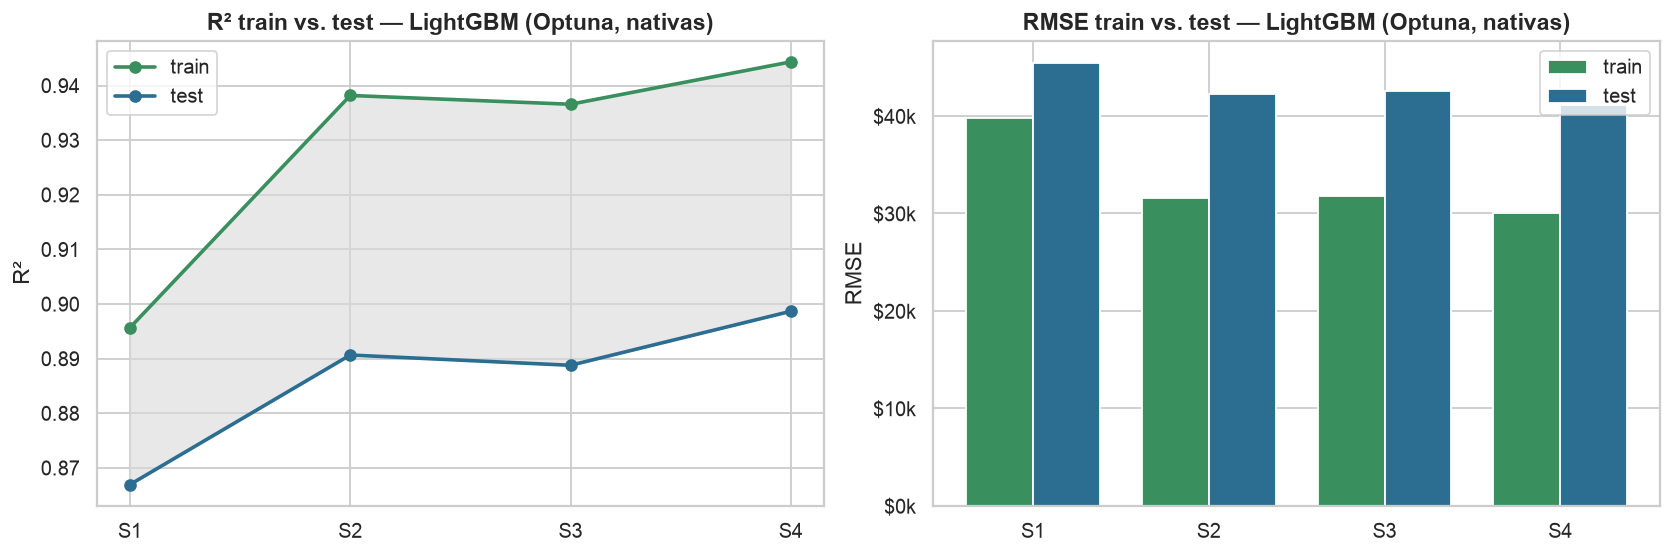

In [3]:
lg_res, lg_oof = {}, {}
for k,cols in escen.items():
    lg_res[k], lg_oof[k] = nested(cols)
tt = pd.DataFrame({k:{"features":len(escen[k]),"R2_train":lg_res[k]["R2_train"],"R2_test":lg_res[k]["R2_test"],
                      "brecha_R2":lg_res[k]["brecha"],"RMSE_train":lg_res[k]["RMSE_train"],
                      "RMSE_test":lg_res[k]["RMSE_test"],"MAPE_test":lg_res[k]["MAPE_test"]} for k in escen}).T
display(tt.round({"features":0,"R2_train":3,"R2_test":3,"brecha_R2":3,"RMSE_train":0,"RMSE_test":0,"MAPE_test":1}))
(ROOT/"reports"/"tables"/"modelado").mkdir(parents=True, exist_ok=True)
tt.rename(columns={"features":"n_features"}).rename_axis("escenario").to_csv(ROOT/"reports"/"tables"/"modelado"/"lightgbm_optuna_s1_s4.csv")

fig,axs=plt.subplots(1,2,figsize=(13,4.4)); x=np.arange(len(escen))
axs[0].plot(x,tt["R2_train"],"o-",color=ACCENT,lw=2,label="train"); axs[0].plot(x,tt["R2_test"],"o-",color=PAL,lw=2,label="test")
axs[0].fill_between(x,tt["R2_test"],tt["R2_train"],color="0.85",alpha=.6)
axs[0].set(title="R² train vs. test — LightGBM (Optuna, nativas)",ylabel="R²",xticks=x); axs[0].set_xticklabels(list(escen)); axs[0].legend()
axs[1].bar(x-0.19,tt["RMSE_train"],0.38,color=ACCENT,label="train"); axs[1].bar(x+0.19,tt["RMSE_test"],0.38,color=PAL,label="test")
axs[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v,_:f"${v/1e3:.0f}k"))
axs[1].set(title="RMSE train vs. test — LightGBM (Optuna, nativas)",ylabel="RMSE",xticks=x); axs[1].set_xticklabels(list(escen)); axs[1].legend()
plt.show()

**Lectura.** El test mejora al incorporar información (R² 0,867 en S1 → 0,899 en S4; RMSE ~USD 45k
→ ~USD 41k), con el mayor incremento en el bloque de **localización (S2)**; la microlocalización (S3)
aporta poco. La **brecha train–test** se mantiene contenida (~0,03 en S1 y ~0,05 en S2–S4): el *early
stopping* y la regularización que elige Optuna limitarían el sobreajuste. La comparación cuantitativa
contra el baseline (one-hot + búsqueda aleatoria) se presenta a continuación.

## 2. LightGBM baseline (04) vs. idiomático (este notebook)

Traemos los resultados del LightGBM baseline (`lightgbm_s1_s4.csv`, one-hot + `RandomizedSearchCV`) y los
ponemos lado a lado, en **test**, con la versión idiomática (categóricas nativas + Optuna + early stopping).

,base_R2,adv_R2,base_RMSE,adv_RMSE,base_brecha,adv_brecha,ΔR2,ΔRMSE
escenario,,,,,,,,
S1,0.864,0.867,45448,45435.0,0.043,0.029,0.003,-13.0
S2,0.890,0.891,42102,42194.0,0.042,0.048,0.001,92.0
S3,0.889,0.889,42388,42510.0,0.047,0.048,-0.000,122.0
S4,0.902,0.899,40336,41126.0,0.047,0.046,-0.003,790.0


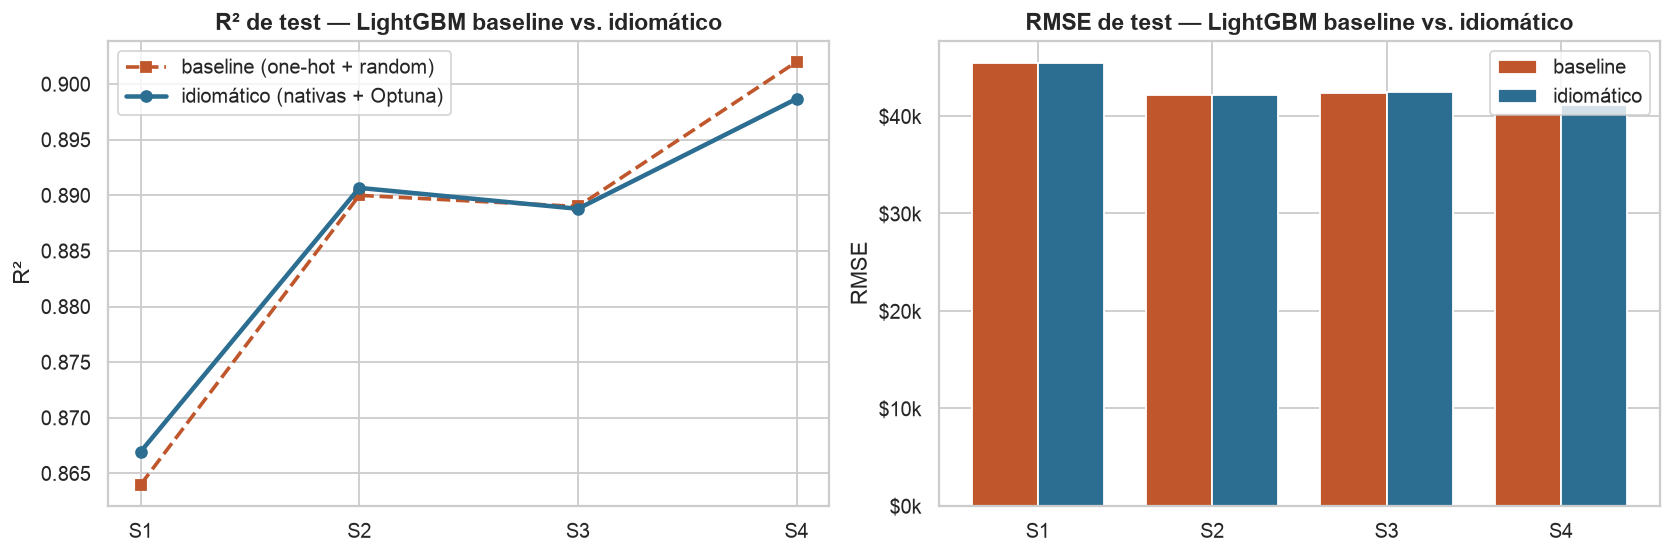

In [4]:
base_path = ROOT/"reports"/"tables"/"modelado"/"lightgbm_s1_s4.csv"
base = pd.read_csv(base_path).set_index("escenario") if base_path.exists() else None

filas=[]
for k in escen:
    row={"escenario":k,
         "base_R2":(base.loc[k,"R2_test"] if base is not None else np.nan), "adv_R2":lg_res[k]["R2_test"],
         "base_RMSE":(base.loc[k,"RMSE_test"] if base is not None else np.nan), "adv_RMSE":lg_res[k]["RMSE_test"],
         "base_brecha":(base.loc[k,"brecha_R2"] if base is not None else np.nan), "adv_brecha":lg_res[k]["brecha"]}
    filas.append(row)
comp=pd.DataFrame(filas).set_index("escenario")
comp["ΔR2"]=comp["adv_R2"]-comp["base_R2"]; comp["ΔRMSE"]=comp["adv_RMSE"]-comp["base_RMSE"]
display(comp.round({c:(3 if ("R2" in c or "brecha" in c) else 0) for c in comp.columns}))

fig,axs=plt.subplots(1,2,figsize=(13,4.4)); x=np.arange(len(escen)); w=.38
if base is not None: axs[0].plot(x,comp["base_R2"],"s--",color=PAL2,lw=2,label="baseline (one-hot + random)")
axs[0].plot(x,comp["adv_R2"],"o-",color=PAL,lw=2.5,label="idiomático (nativas + Optuna)")
axs[0].set(title="R² de test — LightGBM baseline vs. idiomático",ylabel="R²",xticks=x); axs[0].set_xticklabels(list(escen)); axs[0].legend()
if base is not None: axs[1].bar(x-w/2,comp["base_RMSE"],w,color=PAL2,label="baseline")
axs[1].bar(x+w/2 if base is not None else x,comp["adv_RMSE"],w,color=PAL,label="idiomático")
axs[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v,_:f"${v/1e3:.0f}k"))
axs[1].set(title="RMSE de test — LightGBM baseline vs. idiomático",ylabel="RMSE",xticks=x); axs[1].set_xticklabels(list(escen)); axs[1].legend()
plt.show()

**Lectura.** Las dos versiones de LightGBM rinden de forma **prácticamente equivalente** en test: las
diferencias de R² son ≤ 0,003 y las de RMSE ≤ ~USD 800, bastante por debajo del desvío entre folds
(~USD 3k). En S4 el **baseline** (one-hot + búsqueda aleatoria) queda incluso marginalmente por delante
(R² 0,902 vs 0,899; RMSE ~USD 40,3k vs ~USD 41,1k). Es decir, las categóricas nativas y el tuneo bayesiano
**no aportarían una mejora material** en este problema. Es un resultado informativo: sugeriría que el
LightGBM del notebook 04 ya se encontraría cerca del techo del modelo, y que ni la representación (one-hot
vs. nativa) ni el algoritmo de búsqueda (aleatorio vs. bayesiano) resultarían determinantes con estos
datos. Las **brechas** train–test son similares en ambas versiones (~0,05 en S4).

## 3. Interpretabilidad con SHAP (modelo final S4)

Los **valores de Shapley** (Lundberg & Lee, 2017) reparten cada predicción entre las variables de forma
consistente. El **beeswarm** muestra, para cada variable, la distribución de aportes (color = valor de la
variable); el **gráfico de barras** resume la importancia global (media del valor absoluto). Ajustamos el
modelo final sobre S4 con la mejor configuración hallada por Optuna.

Mejores hiperparámetros (S4): {'learning_rate': 0.018, 'num_leaves': 76, 'max_depth': 6, 'min_child_samples': 62, 'subsample': 0.6234, 'colsample_bytree': 0.6956, 'reg_alpha': 0.0039, 'reg_lambda': 3.4345}
Nº de árboles por early stopping: 621


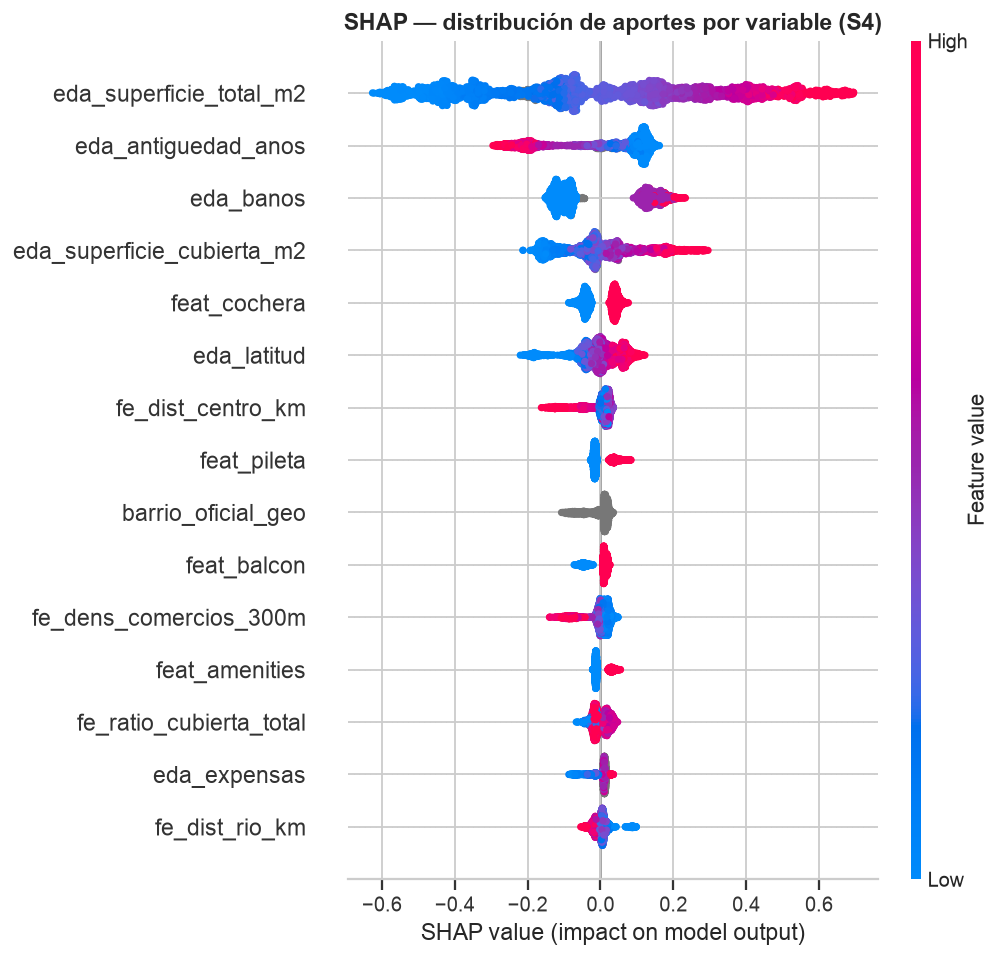

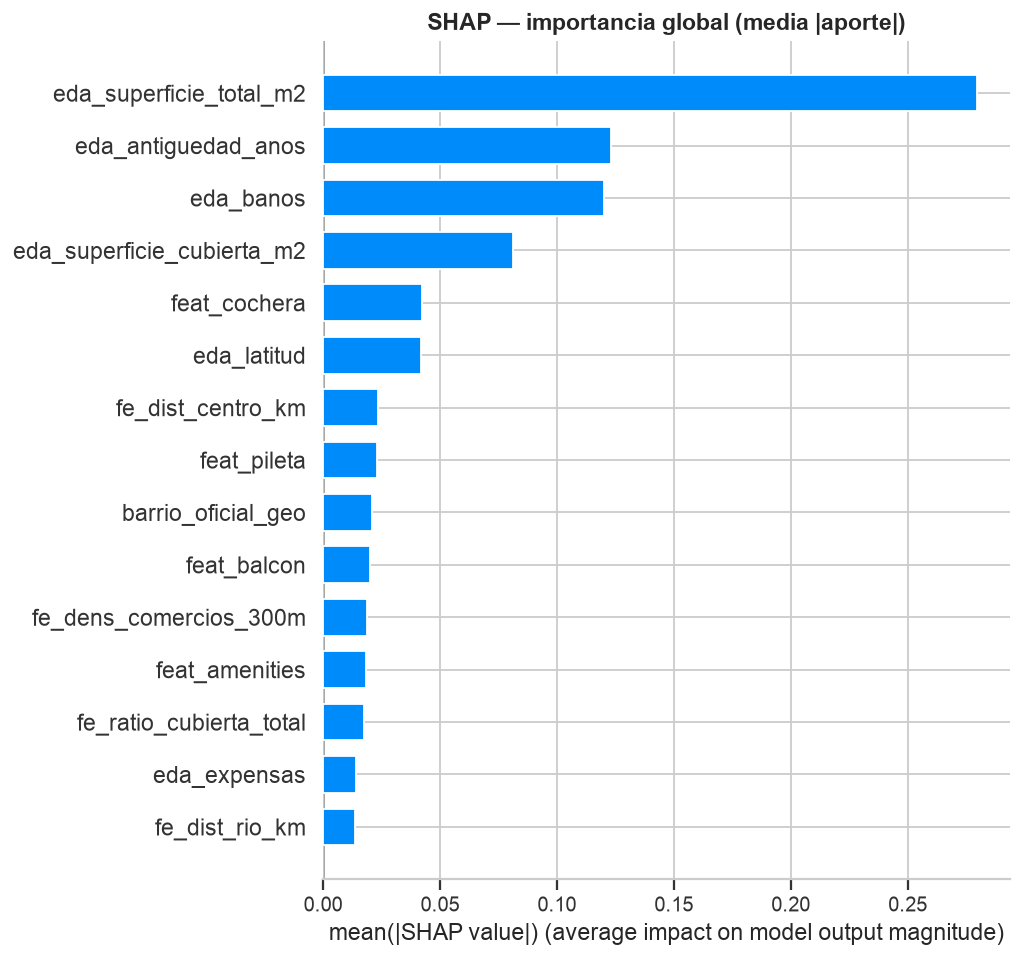

In [5]:
Xs4 = diseno(escen["S4"])
best_s4 = tunear(Xs4, y, groups)
final, itr = ajustar(Xs4, y, groups, best_s4)
print("Mejores hiperparámetros (S4):", {k:(round(v,4) if isinstance(v,float) else v) for k,v in best_s4.items()})
print("Nº de árboles por early stopping:", final.best_iteration_)

expl = shap.TreeExplainer(final)
sv = expl.shap_values(Xs4)
plt.figure()
shap.summary_plot(sv, Xs4, show=False, max_display=15, color_bar=True)
plt.title("SHAP — distribución de aportes por variable (S4)"); plt.tight_layout(); plt.show()

plt.figure()
shap.summary_plot(sv, Xs4, plot_type="bar", show=False, max_display=15)
plt.title("SHAP — importancia global (media |aporte|)"); plt.tight_layout(); plt.show()

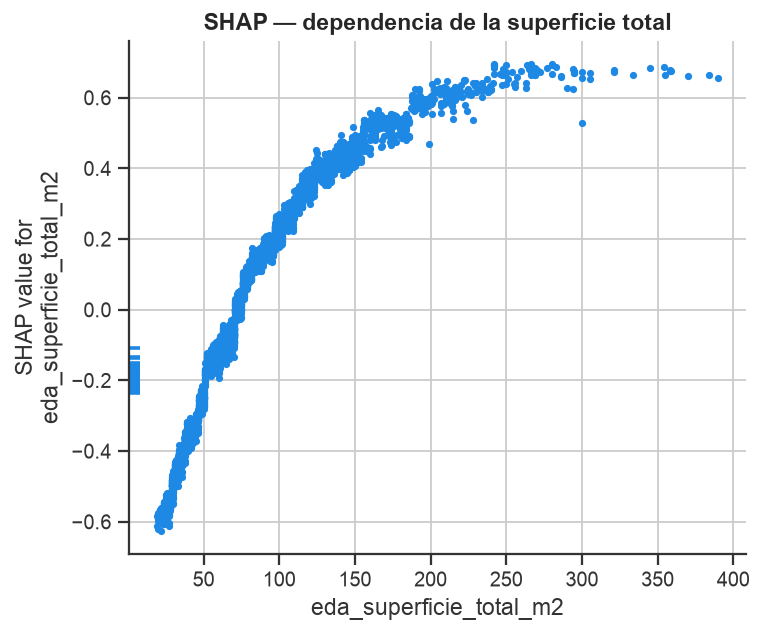

In [6]:
# Dependencia: aporte SHAP de la superficie total vs. su valor
plt.figure()
shap.dependence_plot("eda_superficie_total_m2", sv, Xs4, show=False, interaction_index=None)
plt.title("SHAP — dependencia de la superficie total"); plt.tight_layout(); plt.show()

**Lectura.** El ordenamiento por SHAP resulta **coherente** con la importancia por permutación y con
los coeficientes del hedónico/Lasso: la **superficie total** domina el aporte, seguida por antigüedad,
baños, superficie cubierta y ambientes, con la **latitud** y algunos atributos de texto por debajo. El
*beeswarm* agrega la **dirección** del efecto —mayor superficie tiende a asociarse con mayor aporte al
precio— y el gráfico de **dependencia** muestra esa relación creciente, con una pendiente que se atenúa en
las superficies grandes, lo que sería consistente con la elasticidad menor a 1 estimada en el hedónico
(rendimientos decrecientes). Que un cuarto enfoque —SHAP— reordene las variables en la misma jerarquía
que OLS, Lasso y la importancia del RF aportaría respaldo convergente a la lectura sustantiva. Esta
lectura, local y global, es la base de la etapa de interpretabilidad (RQ5).

## 4. Conclusiones

- **Baseline vs. idiomático: equivalentes.** Las diferencias en test son despreciables (ΔR² ≤ 0,003,
  ΔRMSE ≤ ~USD 800, dentro del ruido entre folds); en S4 el baseline queda incluso marginalmente por
  delante. Las categóricas nativas, Optuna y el early stopping **no aportarían una mejora material** en
  este problema, lo que sería consistente con que el LightGBM ya se encontraría cerca de su techo y con que
  la representación de las categóricas no resultaría determinante con estos datos.
- **Sesgo–varianza.** Las brechas train–test son similares en ambas versiones (~0,05 en S4); el early
  stopping mantendría la brecha contenida.
- **Interpretabilidad (RQ5).** SHAP ofrece una lectura local y global coherente con los otros modelos, y
  agrega la dirección y la forma de los efectos.
- **Elección del modelo final.** Ante el empate, convendría conservar el **LightGBM baseline (04)** por
  simplicidad y comparabilidad directa con el Random Forest, y emplear **SHAP** (de este notebook) como
  capa de interpretabilidad. Ese modelo pasaría a las etapas de **diagnóstico espacial** (Moran's I;
  RQ3–RQ4) e **interpretabilidad** ampliada (RQ5).

## Referencias

**Libros**

- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2ª ed.), cap. 10. Springer.
- Kuhn, M., & Johnson, K. (2013). *Applied Predictive Modeling*. Springer.
- Molnar, C. (2022). *Interpretable Machine Learning* (2ª ed.). — SHAP e importancia.
- van Wyk, A. (2023). *Machine Learning with LightGBM and Python*. Packt.

**Artículos**

- Ke, G., et al. (2017). LightGBM: a highly efficient gradient boosting decision tree. *NeurIPS 30*.
- Friedman, J. H. (2001). Greedy function approximation: a gradient boosting machine. *Annals of Statistics, 29*(5).
- Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). Optuna: a next-generation hyperparameter optimization framework. *KDD*.
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions (SHAP). *NeurIPS 30*.